# Midterm Project

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split

In [6]:
import kagglehub

path = kagglehub.dataset_download(
    "vedauv/what-makes-a-yt-video-go-viral-12000-vids",
    output_dir="./dataset",
    force_download=True
)

print("Path to dataset files:", path)


100%|██████████| 330k/330k [00:00<00:00, 641kB/s]

Extracting files...
Path to dataset files: ./dataset


(Placeholder for explaining how to download the dataset)

## EDA

In [7]:
df = pd.read_csv("./dataset/viral_videos.csv")

df.head(10)

,video_id,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
0,vid_000001,Beauty,517,64,1,23,Wed,27,429,907474,970600,20610,4029,7208,1
1,vid_000002,Tech,495,47,1,23,Mon,10,222,1004641,104278,3907,554,554,0
2,vid_000003,Beauty,311,76,0,17,Mon,13,520,168170,18102,1021,77,122,0
3,vid_000004,Fitness,590,69,0,0,Mon,17,309,285593,52042,2587,142,964,0
4,vid_000005,Tech,380,58,1,19,Mon,0,101,1073326,908509,22993,1825,2611,1
5,vid_000006,Cooking,418,31,1,20,Sat,21,338,429909,51070,2684,190,914,0
6,vid_000007,Cooking,710,70,0,14,Fri,22,248,155341,65872,2625,156,507,0
7,vid_000008,Education,1218,41,0,0,Sun,21,588,967230,178506,11209,1839,3008,0
8,vid_000009,Finance,1057,15,1,13,Wed,21,526,287375,125402,9336,815,2083,0
9,vid_000010,Education,686,66,1,10,Mon,13,371,27624,40108,2899,494,452,0


In [8]:
df.shape

(12000, 15)

Dropping 'video_id' column from the dataframe.

In [9]:
del df['video_id']

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   category            12000 non-null  str  
 1   duration_sec        12000 non-null  int64
 2   title_length        12000 non-null  int64
 3   thumbnail_face      12000 non-null  int64
 4   upload_hour         12000 non-null  int64
 5   upload_day          12000 non-null  str  
 6   tags_count          12000 non-null  int64
 7   description_length  12000 non-null  int64
 8   subscriber_count    12000 non-null  int64
 9   views               12000 non-null  int64
 10  likes               12000 non-null  int64
 11  comments            12000 non-null  int64
 12  shares              12000 non-null  int64
 13  viral               12000 non-null  int64
dtypes: int64(12), str(2)
memory usage: 1.3 MB


No missing values were found.

In [11]:
df.describe().round(2)

,duration_sec,title_length,thumbnail_face,upload_hour,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
count,12000.00,12000.00,12000.00,12000.00,12000.00,12000.00,1.200000e+04,1.200000e+04,12000.00,12000.00,12000.00,12000.0
mean,631.62,54.52,0.40,11.54,14.59,508.92,1.009487e+06,7.677524e+05,37505.78,4739.63,9503.24,0.2
std,285.83,14.95,0.49,6.91,7.74,287.21,2.585562e+06,3.526908e+06,182311.46,23313.87,46444.99,0.4
min,30.00,10.00,0.00,0.00,0.00,0.00,3.636000e+03,1.390000e+02,6.00,0.00,1.00,0.0
25%,408.00,45.00,0.00,5.00,9.00,300.00,1.585215e+05,6.123550e+04,2790.00,316.75,641.75,0.0
50%,614.00,55.00,0.00,12.00,14.00,504.00,3.813820e+05,1.852680e+05,8751.50,1018.00,2050.50,0.0
75%,822.00,65.00,1.00,18.00,20.00,709.00,9.298448e+05,5.569705e+05,26571.25,3207.25,6527.25,0.0
max,1960.00,109.00,1.00,23.00,44.00,1618.00,1.000000e+08,1.994657e+08,11592871.00,1116186.00,2367174.00,1.0


Check for duplicate rows.

In [12]:
df.duplicated().sum()


np.int64(0)

Visualize the distribution of the target variable.

<Axes: xlabel='viral', ylabel='count'>

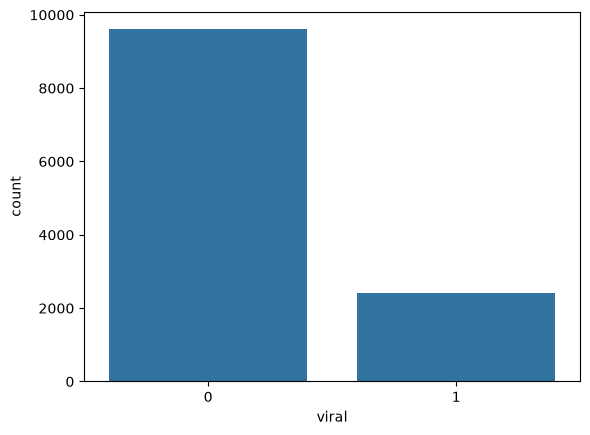

In [13]:
sns.countplot(x="viral", data=df)

In [14]:
df["viral"].value_counts(normalize=True) * 100

viral
0    80.0
1    20.0
Name: proportion, dtype: float64

Target variable is asymmetric, this will be important to consider when evaluating the model.

Since the target variable is derived from the 'views' feature (20% most viewed videos), we will have to drop it from the dataset to prevent leakage.

In [15]:
df.drop(['views'], axis=1, inplace=True)

Split the dataset into train and test sets (the validation set is handled by GridSearchCV/RandomizedSearchCV). Use stratified sampling to ensure that the distribution of the target variable is similar in all sets.

In [16]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["viral"])
len(df_train), len(df_test)

(9600, 2400)

In [17]:
df_train.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)

y_train = df_train["viral"]
y_test = df_test["viral"]

In [18]:
numerical = ["duration_sec", "title_length", "tags_count", "description_length", "subscriber_count", "likes", "comments", "shares", "viral"]

categorical = ["category", "thumbnail_face", "upload_hour", "upload_day"]

### NUMERICAL FEATURE ANALYSIS

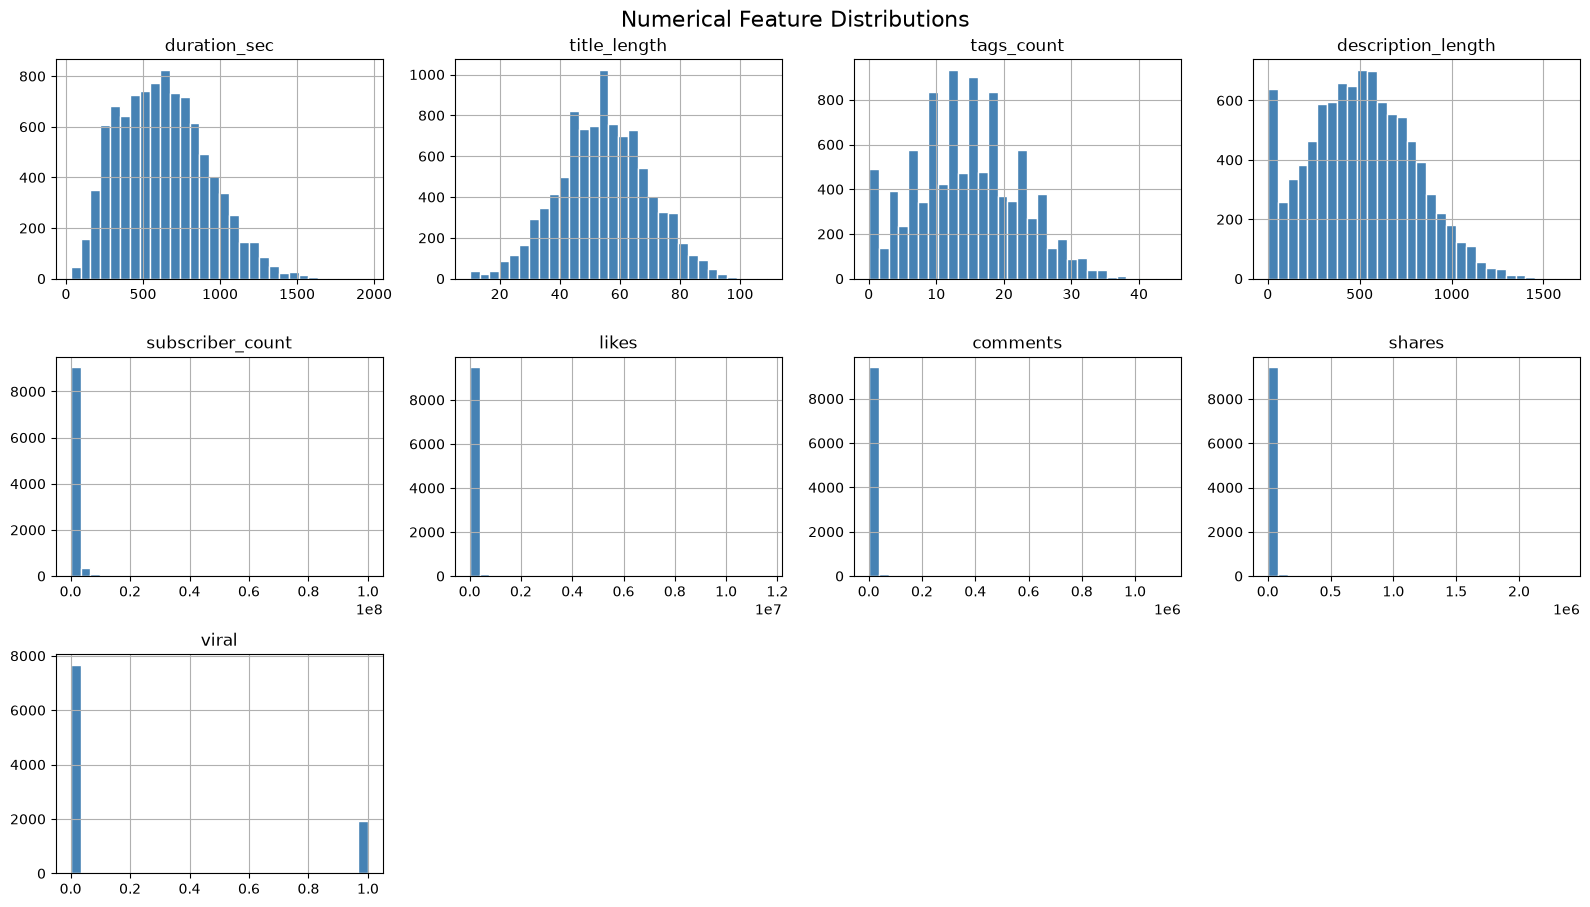

In [19]:
df_train[numerical].hist(bins=30, figsize=(16, 12), 
                        layout=(4, 4), color='steelblue', 
                        edgecolor='white')
plt.suptitle('Numerical Feature Distributions', fontsize=16)
plt.tight_layout()
plt.show()

We can see that most of the numerical features are right skewed, which is common in social media data. We will apply log transformation to these features to make them more normally distributed (consider box plot for outlier detection). This is essential for the logistic regression model, as it requires the features to be normally distributed for better performance, but isn't strictly necessary for tree-based models.

In [20]:
df_train_log = df_train.copy()

for col in ["subscriber_count", "likes", "comments", "shares"]:
    df_train_log[f"{col}_log"] = np.log1p(df_train_log[col])

Created a separate DataFrame with log-transformed features

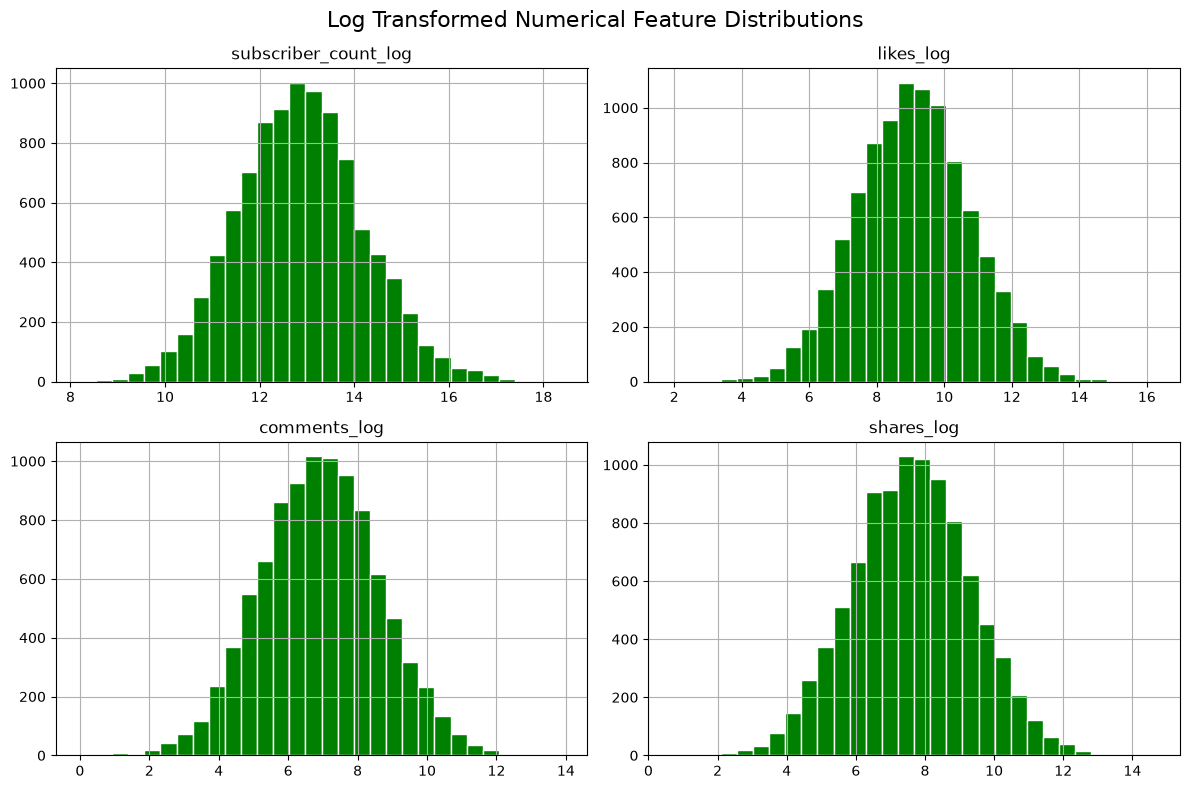

In [21]:
df_train_log[["subscriber_count_log", "likes_log", "comments_log", "shares_log"]].hist(bins=30,
                        figsize=(12, 8), color='green', 
                        edgecolor='white')
plt.suptitle('Log Transformed Numerical Feature Distributions', fontsize=16)
plt.tight_layout()
plt.show()

### CATEGORICAL FEATURE ANALYSIS

category: 15 unique values


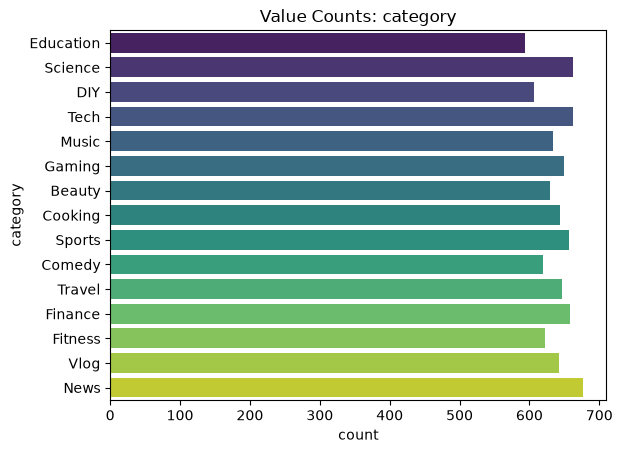

thumbnail_face: 2 unique values


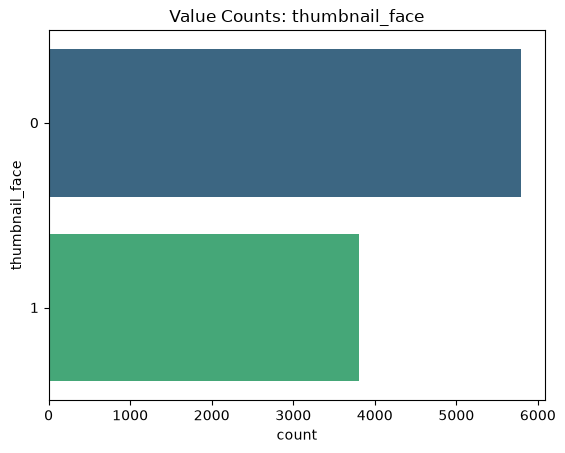

upload_hour: 24 unique values


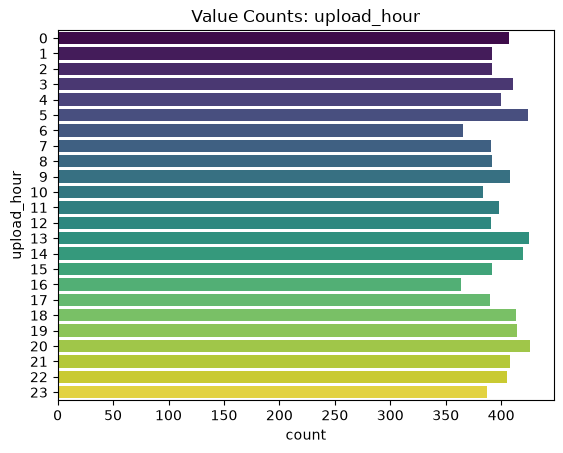

upload_day: 7 unique values


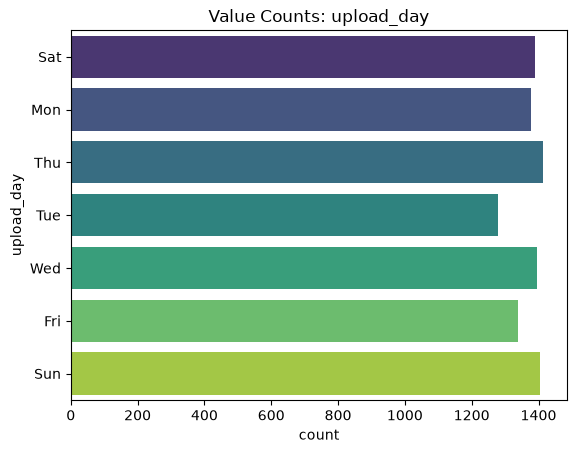

In [22]:
for cat in categorical:
    n_unique = df_train[cat].nunique()
    print(f"{cat}: {n_unique} unique values")
    
    if n_unique <= 24:
        sns.countplot(y=cat, data=df_train, palette='viridis', hue=cat, legend=None)
        plt.title(f'Value Counts: {cat}')
        plt.show()

### FEATURE IMPORTANCE ANALYSIS (part of EDA)

#### RISK RATIO

In [23]:
from IPython.display import display

global_viral = df_train.viral.mean()

for cat in categorical:
    print(cat)
    df_group = df_train.groupby(cat).viral.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_viral
    df_group['risk'] = df_group['mean'] / global_viral
    display(df_group)

category


,mean,count,diff,risk
category,,,,
Beauty,0.219396,629,0.019396,1.096979
Comedy,0.365105,619,0.165105,1.825525
Cooking,0.170807,644,-0.029193,0.854037
DIY,0.128713,606,-0.071287,0.643564
Education,0.116358,593,-0.083642,0.581788
Finance,0.139818,658,-0.060182,0.699088
Fitness,0.118971,622,-0.081029,0.594855
Gaming,0.257319,649,0.057319,1.286595
Music,0.582019,634,0.382019,2.910095


thumbnail_face


,mean,count,diff,risk
thumbnail_face,,,,
0,0.182289,5793,-0.017711,0.911445
1,0.226950,3807,0.026950,1.134752


upload_hour


,mean,count,diff,risk
upload_hour,,,,
0,0.211302,407,0.011302,1.056511
1,0.163265,392,-0.036735,0.816327
2,0.158163,392,-0.041837,0.790816
3,0.170316,411,-0.029684,0.851582
4,0.210000,400,0.010000,1.050000
5,0.205189,424,0.005189,1.025943
6,0.193989,366,-0.006011,0.969945
7,0.225064,391,0.025064,1.125320
8,0.206633,392,0.006633,1.033163


upload_day


,mean,count,diff,risk
upload_day,,,,
Fri,0.203883,1339,0.003883,1.019417
Mon,0.211901,1378,0.011901,1.059507
Sat,0.186916,1391,-0.013084,0.934579
Sun,0.192883,1405,-0.007117,0.964413
Thu,0.205799,1414,0.005799,1.028996
Tue,0.196247,1279,-0.003753,0.981235
Wed,0.202296,1394,0.002296,1.011478


It seems that certain classes within the different categorical features increase the probability of the target being positive i.e. the "comedy" class is almost twice as likely to make a video viral. Apparently,
upload_day and upload_hour by themselves don't influence much the probability of virality, however after some research, we suspect that combining these features (through feature engineering) might yield a better predictor variable.

#### MUTUAL INFORMATION

In [24]:
from sklearn.metrics import mutual_info_score

def mutual_info_viral_score(series):
    return mutual_info_score(series, df_train.viral)

info_gain = df_train[categorical].apply(mutual_info_viral_score)
info_gain.sort_values(ascending=False)

category          0.045265
thumbnail_face    0.001477
upload_hour       0.001173
upload_day        0.000195
dtype: float64

The mutual information score confirms what was suggested by risk ratio analysis: the "category" feature seems to wield more predictive value than the rest of the categorical features.

#### CORRELATION ANALYSIS

In [25]:
df_train[numerical].corr()

,duration_sec,title_length,tags_count,description_length,subscriber_count,likes,comments,shares,viral
duration_sec,1.000000,0.003593,-0.002113,-0.000373,-0.171559,-0.090953,-0.092639,-0.094384,-0.164612
title_length,0.003593,1.000000,-0.007105,-0.002825,0.002511,0.010425,0.008206,0.009590,-0.002305
tags_count,-0.002113,-0.007105,1.000000,0.004313,0.010814,0.017301,0.017144,0.017537,0.026662
description_length,-0.000373,-0.002825,0.004313,1.000000,-0.007474,-0.001355,0.002585,0.001355,-0.014431
subscriber_count,-0.171559,0.002511,0.010814,-0.007474,1.000000,0.663346,0.612804,0.640756,0.402984
likes,-0.090953,0.010425,0.017301,-0.001355,0.663346,1.000000,0.961569,0.963020,0.293353
comments,-0.092639,0.008206,0.017144,0.002585,0.612804,0.961569,1.000000,0.937596,0.293365
shares,-0.094384,0.009590,0.017537,0.001355,0.640756,0.963020,0.937596,1.000000,0.292287
viral,-0.164612,-0.002305,0.026662,-0.014431,0.402984,0.293353,0.293365,0.292287,1.000000


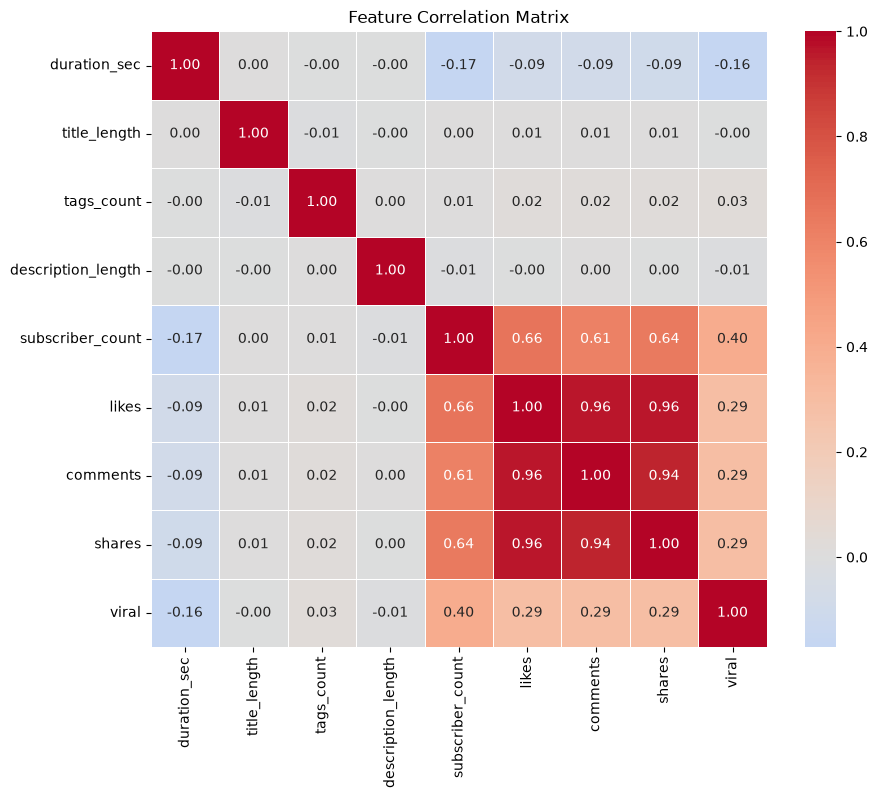

In [26]:
plt.figure(figsize=(10, 8))
corr_matrix = df_train[numerical].corr()

sns.heatmap(corr_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.show()

Pearson correlation measures linear relationships, hence it is affected by outliers that skew data. Therefore we use the log transformed numerical features and repeated the analysis.

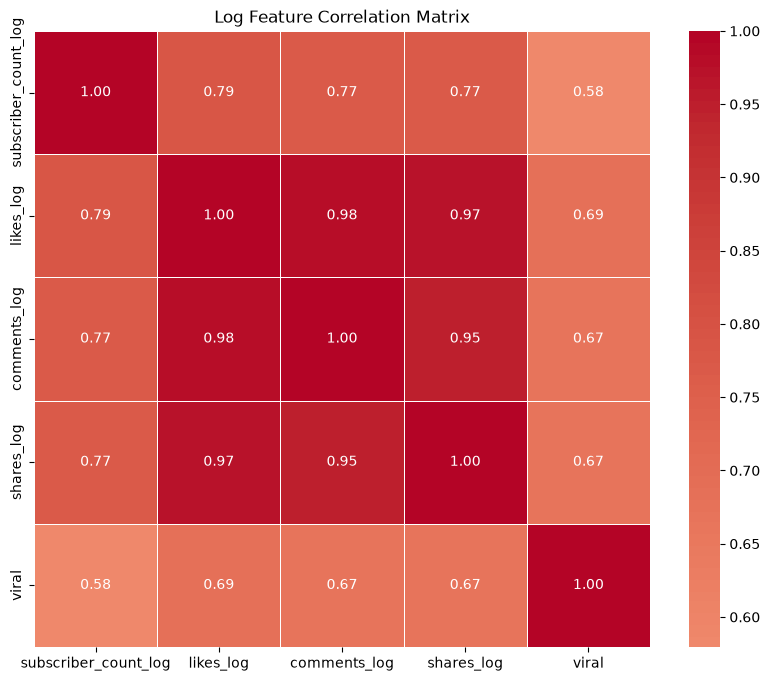

In [27]:
plt.figure(figsize=(10, 8))
corr_matrix = df_train_log[["subscriber_count_log", "likes_log", "comments_log", "shares_log", "viral"]].corr()

sns.heatmap(corr_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5)
plt.title('Log Feature Correlation Matrix')
plt.show()

Correlations increased significantly between the log transformed features and the target. Also, there seems to be multi-collinearity between 'shares', 'comments' and 'likes', which given our domain knowledge is expected, as these metrics are often interrelated in social media content. Due to the fact that these features aren't useful for predicting virality beforehand (and would introduce leakage to the model), it makes sense to drop them from the dataset.

(think about feature engineering upload_day/upload_hour into bins for tree-based, and sin/cos for linear model)

## MODEL TRAINING

In [28]:
df_train.drop(['viral', 'shares', 'comments', 'likes'], axis=1, inplace=True)
df_test.drop(['viral', 'shares', 'comments', 'likes'], axis=1, inplace=True)

### Decision Tree

In [29]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.feature_extraction import DictVectorizer

In [30]:
train_dicts = df_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_test = dv.transform(df_test.to_dict(orient='records'))

In [31]:
dt = DecisionTreeClassifier(random_state=42)

In [32]:
param_grid = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["entropy"]
}

grid_search_dt = GridSearchCV(estimator=dt, 
                           param_grid=param_grid, 
                           cv=5, 
                           scoring='roc_auc', 
                           n_jobs=-1, 
                           verbose=1,
                           return_train_score=True)

print("Initializing hyperparameter search")
grid_search_dt.fit(X_train, y_train)

print("\n--- Search Results ---")
print(f"Best parameters: {grid_search_dt.best_params_}")
print(f"Best cross-validated training ROC AUC: {grid_search_dt.best_score_:.4f}")



Initializing hyperparameter search
Fitting 5 folds for each of 12 candidates, totalling 60 fits

--- Search Results ---
Best parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1}
Best cross-validated training ROC AUC: 0.9000


### Random Forest

In [33]:
from sklearn.ensemble import RandomForestClassifier

In [34]:
rf = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 12, 14],
    'min_samples_leaf': [10, 20, 40],
    'class_weight': ['balanced']
}

grid_search_rf = GridSearchCV(estimator=rf, 
                           param_grid=param_grid, 
                           cv=5, 
                           scoring='roc_auc', 
                           n_jobs=-1, 
                           verbose=1,
                           return_train_score=True)

print("Initializing hyperparameter search")
grid_search_rf.fit(X_train, y_train)

print("\n--- Search Results ---")
print(f"Best parameters: {grid_search_rf.best_params_}")
print(f"Best cross-validated training ROC AUC: {grid_search_rf.best_score_:.4f}")

Initializing hyperparameter search
Fitting 5 folds for each of 27 candidates, totalling 135 fits

--- Search Results ---
Best parameters: {'class_weight': 'balanced', 'max_depth': 14, 'min_samples_leaf': 20, 'n_estimators': 200}
Best cross-validated training ROC AUC: 0.8983


### XGBoost

In [ ]:
import xgboost as xgb


In [ ]:
xgb_model = xgb.XGBClassifier(random_state=42)

param_grid = {'eta': [0.01, 0.05, 0.1, 0.3],
    'max_depth': [3, 4, 6],
    'min_child_weight': [1, 10, 30],
    'n_estimators': [100, 200, 300],
    'objective': ['binary:logistic'],
    'nthread': [8],
    'seed': [42],
    'verbosity': [1],
}

grid_search_xgb = GridSearchCV(estimator=xgb_model, 
                               param_grid=param_grid, 
                               scoring='roc_auc', 
                               n_jobs=-1, 
                               cv=5, 
                               verbose=1)

print("Initializing hyperparameter search")
grid_search_xgb.fit(X_train, y_train)

print("\n--- Search Results ---")
print(f"Best parameters: {grid_search_xgb.best_params_}")
print(f"Best cross-validated training ROC AUC: {grid_search_xgb.best_score_:.4f}")



Initializing hyperparameter search
Fitting 5 folds for each of 108 candidates, totalling 540 fits

--- Search Results ---
Best parameters: {'eta': 0.01, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 300, 'nthread': 8, 'objective': 'binary:logistic', 'seed': 42, 'verbosity': 1}
Best cross-validated training ROC AUC: 0.9067


## Final Model Selection

The model ROC AUC scores on the cross-validation are  Decision Tree: 0.9000, Random Forest: 0.8983, XGBoost: 0.9067

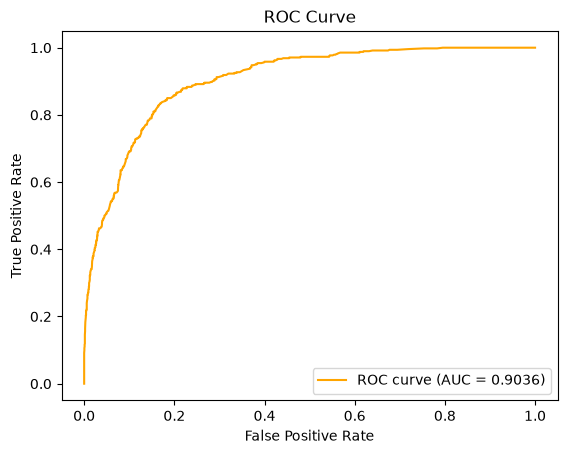

Final ROC AUC on test set: 0.9036


In [ ]:
from sklearn.metrics import roc_curve, auc

xgb_final_model = grid_search_xgb.best_estimator_

xgb_final_model.fit(X_train, y_train)

y_pred = xgb_final_model.predict_proba(X_test)[:, 1]
fpr, tpr, threshold = roc_curve(y_test, y_pred)
test_roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='orange', label=f"ROC curve (AUC = {test_roc_auc:.4f})")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

print(f"Final ROC AUC on test set: {test_roc_auc:.4f}")

## Pipeline Build

In [ ]:
from sklearn.pipeline import make_pipeline

pipeline = make_pipeline(DictVectorizer(), 
                        xgb_final_model)

pipeline.fit(train_dicts, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('xgbclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",True
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


## Saving the Model

In [ ]:
import pickle

with open("model.bin", "wb") as f_out:
    pickle.dump(pipeline, f_out)
    

## Loading the Model

In [ ]:
with open("model.bin", "rb") as f_out:
    pipeline = pickle.load(f_out)

sample = train_dicts[0]
sample_pred = pipeline.predict_proba([sample])[:, 1]

print(sample_pred)

[0.73706216]
